,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero


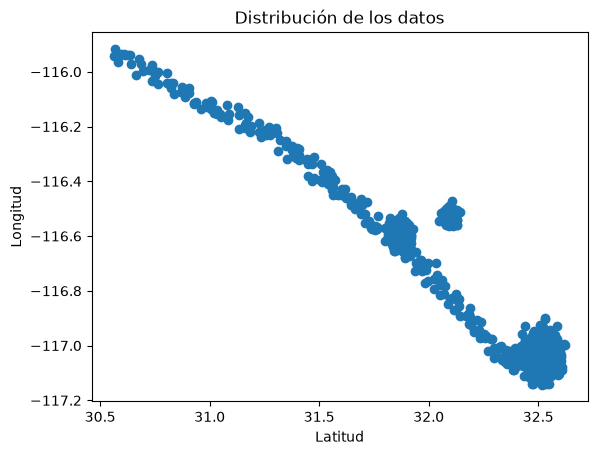

array([[ 0.88335238, -0.73514142],
       [ 1.00618974, -0.94540065],
       [ 0.72294016, -1.00890342],
       [ 0.85594675, -0.85748798],
       [ 0.82294302, -0.84072749]])

In [22]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

scaler = StandardScaler()

df = pd.read_csv('data.csv')
display(df.head())

plt.scatter(df['Latitud'], df['Longitud'])
plt.xlabel('Latitud')
plt.ylabel('Longitud')
plt.title('Distribución de los datos')
plt.show()

X_scaled = scaler.fit_transform(df[['Latitud', 'Longitud']])
display(X_scaled[:5])

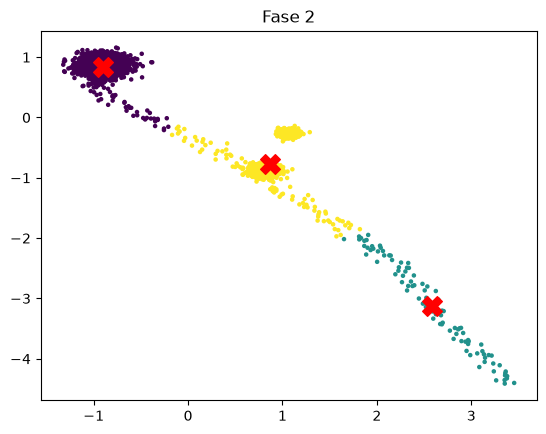

Centros de los clústeres:
     Latitud    Longitud
0  32.506316 -117.034964
1  31.040540 -116.138027
2  31.912348 -116.580728
0    1611
1      95
2    1394
Name: count, dtype: int64


In [23]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
centros = kmeans.cluster_centers_
plt.scatter(X_scaled[:, 1], X_scaled[:, 0], c=kmeans.labels_, s=5, cmap='viridis')
plt.scatter(centros[:, 1], centros[:, 0], c='red', marker='X', s=200)
plt.title('Fase 2')
plt.show()

print("Centros de los clústeres:")
centros_reales = scaler.inverse_transform(centros)
print(pd.DataFrame(centros_reales, columns=['Latitud', 'Longitud']))
print(pd.Series(kmeans.labels_).value_counts().sort_index())

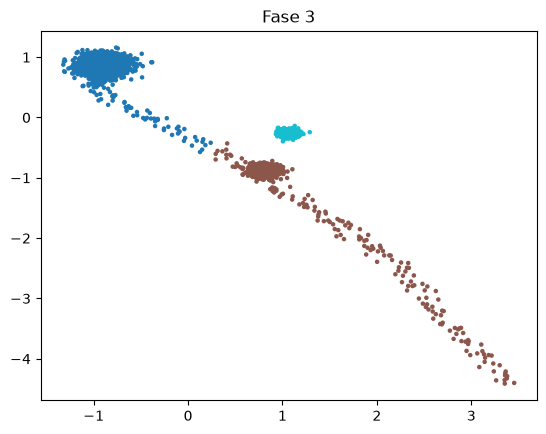

0    1629
1    1171
2     300
Name: count, dtype: int64


In [24]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.15, min_samples=3).fit(X_scaled)
plt.scatter(X_scaled[:, 1], X_scaled[:, 0], c=db.labels_, s=5, cmap='tab10')
plt.title('Fase 3')
plt.show()
print(pd.Series(db.labels_).value_counts().sort_index())

### Análisis — Fase 3 (escribir aquí)
- ¿Usaron el mismo algoritmo que en la misión anterior? No, usamos clustering por densidad para encontrar donde realmente se encuentran los centros de personas
- ¿De no ser así, porqué se comportaron diferentes? Kmeans distribuye los clusteres por proximidad y DBSCAN busca por densidad de datos deshaciendose de ruido
- ¿A qué ciudades reales corresponden las 3 manchas urbanas que encontró su algoritmo? Ensenada Tijuana y Valle de Guadalupe